In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/raw/imoveis.csv")
df.head()

,city,area,rooms,bathroom,parking_spaces,floor,animal,furniture,hoa_(BRL),rent_amount_(BRL),property_tax_(BRL),fire_insurance_(BRL),total_(BRL)
0,Sao Paulo,70,2,1,1,7,acept,furnished,2065,3300,211,42,5618
1,Sao Paulo,320,4,4,0,20,acept,not furnished,1200,4960,1750,63,7973
2,Porto Alegre,80,1,1,1,6,acept,not furnished,1000,2800,0,41,3841
3,Porto Alegre,51,2,1,0,2,acept,not furnished,270,1112,22,17,1421
4,Sao Paulo,25,1,1,0,1,not acept,not furnished,0,800,25,11,836


In [2]:
df.info()
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10692 entries, 0 to 10691
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   city                  10692 non-null  str  
 1   area                  10692 non-null  int64
 2   rooms                 10692 non-null  int64
 3   bathroom              10692 non-null  int64
 4   parking_spaces        10692 non-null  int64
 5   floor                 10692 non-null  int64
 6   animal                10692 non-null  str  
 7   furniture             10692 non-null  str  
 8   hoa_(BRL)             10692 non-null  int64
 9   rent_amount_(BRL)     10692 non-null  int64
 10  property_tax_(BRL)    10692 non-null  int64
 11  fire_insurance_(BRL)  10692 non-null  int64
 12  total_(BRL)           10692 non-null  int64
dtypes: int64(10), str(3)
memory usage: 1.4 MB
city                    0
area                    0
rooms                   0
bathroom                0
parking_spaces  

,count,mean,std,min,25%,50%,75%,max
area,10692.0,149.217920,537.016942,11.0,56.00,90.0,182.0,46335.0
rooms,10692.0,2.506079,1.171266,1.0,2.00,2.0,3.0,13.0
bathroom,10692.0,2.236813,1.407198,1.0,1.00,2.0,3.0,10.0
parking_spaces,10692.0,1.609147,1.589521,0.0,0.00,1.0,2.0,12.0
floor,10692.0,5.067995,6.069050,0.0,1.00,3.0,8.0,301.0
hoa_(BRL),10692.0,1174.021698,15592.305248,0.0,170.00,560.0,1237.5,1117000.0
rent_amount_(BRL),10692.0,3896.247194,3408.545518,450.0,1530.00,2661.0,5000.0,45000.0
property_tax_(BRL),10692.0,366.704358,3107.832321,0.0,38.00,125.0,375.0,313700.0
fire_insurance_(BRL),10692.0,53.300879,47.768031,3.0,21.00,36.0,68.0,677.0
total_(BRL),10692.0,5490.487000,16484.725912,499.0,2061.75,3581.5,6768.0,1120000.0


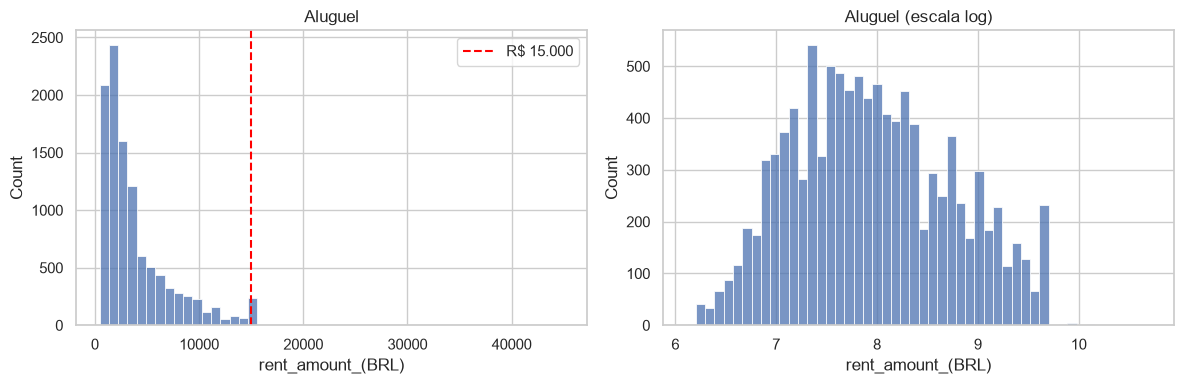

In [12]:
from pathlib import Path
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["rent_amount_(BRL)"], bins=50, ax=ax[0])
ax[0].axvline(15000, color="red", linestyle="--", label="R$ 15.000")
ax[0].legend()
ax[0].set_title("Aluguel")
sns.histplot(np.log1p(df["rent_amount_(BRL)"]), bins=50, ax=ax[1])
ax[1].set_title("Aluguel (escala log)")
plt.tight_layout()
plt.savefig("../reports/figures/distribuicao_aluguel.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
cols = ["area", "hoa_(BRL)", "property_tax_(BRL)", "rent_amount_(BRL)"]
print(df[cols].quantile([0.5, 0.9, 0.99, 0.999]))
for c in cols:
    print(c, df[c].nlargest(5).tolist())

          area  hoa_(BRL)  property_tax_(BRL)  rent_amount_(BRL)
0.500    90.00      560.0             125.000             2661.0
0.900   300.00     2333.8             890.900             8959.0
0.990   650.09     5000.0            2704.000            15000.0
0.999  1000.00     9930.9            6517.078            18309.0
area [46335, 24606, 12732, 2000, 2000]
hoa_(BRL) [1117000, 1117000, 220000, 200000, 81150]
property_tax_(BRL) [313700, 28120, 21880, 12500, 10830]
rent_amount_(BRL) [45000, 30000, 25000, 24000, 20000]


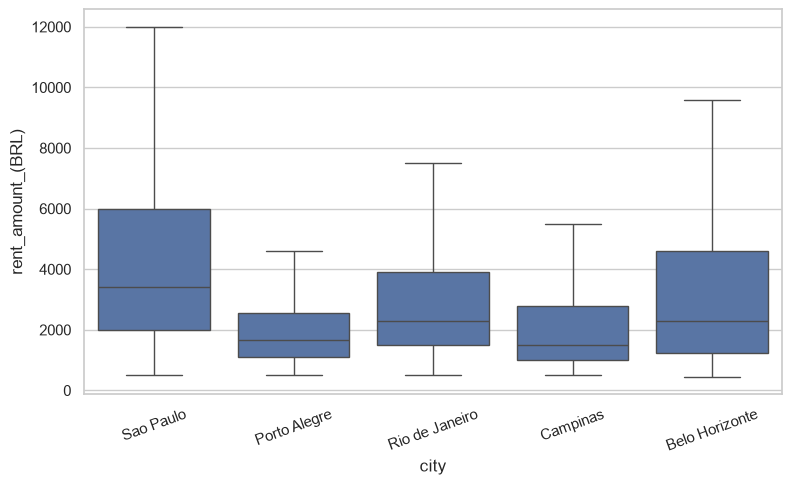

In [6]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="city", y="rent_amount_(BRL)", showfliers=False)
plt.xticks(rotation=20)
plt.show()

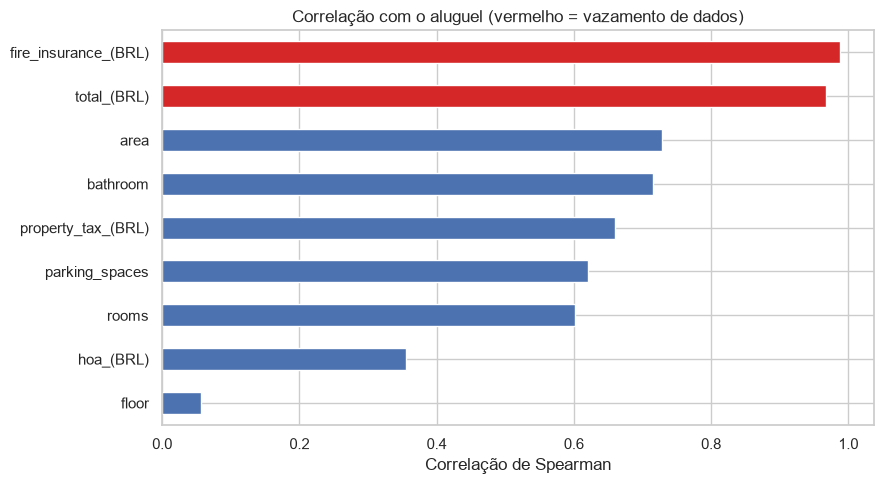

In [8]:
corr_alvo = (df.select_dtypes("number")
               .corr(method="spearman")["rent_amount_(BRL)"]
               .drop("rent_amount_(BRL)")
               .sort_values())

cores = ["#d62728" if c in ["fire_insurance_(BRL)", "total_(BRL)"] else "#4c72b0"
         for c in corr_alvo.index]

plt.figure(figsize=(9, 5))
corr_alvo.plot(kind="barh", color=cores)
plt.title("Correlação com o aluguel (vermelho = vazamento de dados)")
plt.xlabel("Correlação de Spearman")
plt.tight_layout()
plt.savefig("../reports/figures/correlacao_vazamento.png", dpi=150, bbox_inches="tight")
plt.show()

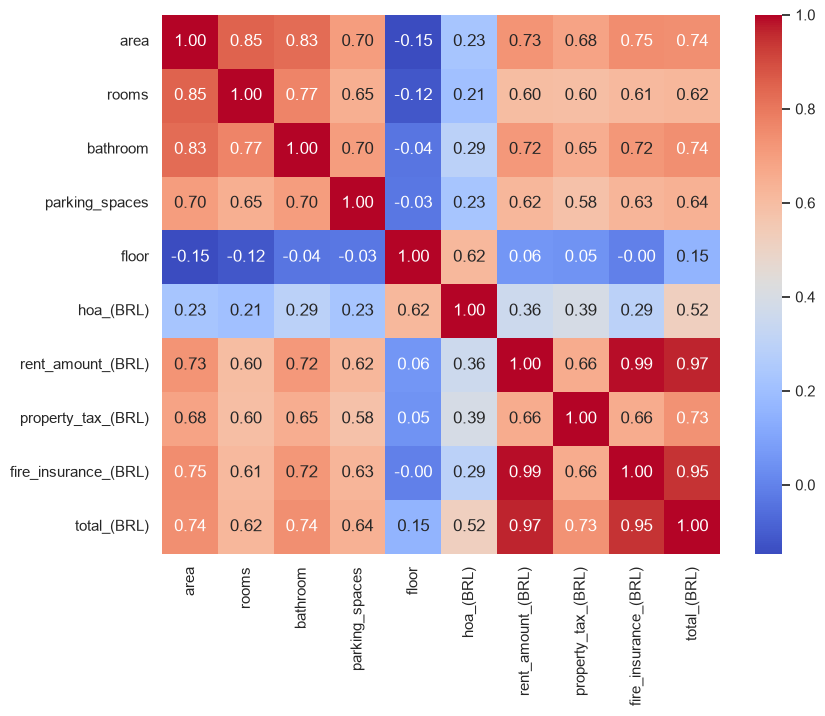

rent_amount_(BRL)       1.000000
fire_insurance_(BRL)    0.988045
total_(BRL)             0.968176
area                    0.728095
bathroom                0.715890
property_tax_(BRL)      0.659230
parking_spaces          0.620175
rooms                   0.600969
hoa_(BRL)               0.355785
floor                   0.056828
Name: rent_amount_(BRL), dtype: float64

In [9]:
num = df.select_dtypes("number")
corr = num.corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()
corr["rent_amount_(BRL)"].sort_values(ascending=False)

In [10]:
for c in ["city", "floor", "animal", "furniture"]:
    print(df[c].value_counts().head(10), "\n")

city
Sao Paulo         5887
Rio de Janeiro    1501
Belo Horizonte    1258
Porto Alegre      1193
Campinas           853
Name: count, dtype: int64 

floor
0    2461
1    1081
2     985
3     931
4     748
5     600
6     539
7     497
8     490
9     369
Name: count, dtype: int64 

animal
acept        8316
not acept    2376
Name: count, dtype: int64 

furniture
not furnished    8086
furnished        2606
Name: count, dtype: int64 



In [11]:
df["aluguel_m2"] = df["rent_amount_(BRL)"] / df["area"]
df.groupby("city")["aluguel_m2"].median().sort_values(ascending=False)

city
Sao Paulo         30.555556
Rio de Janeiro    29.906542
Porto Alegre      22.222222
Belo Horizonte    20.000000
Campinas          18.333333
Name: aluguel_m2, dtype: float64

## Conclusões da análise exploratória

**Visão geral.** O dataset tem 10.692 imóveis e 13 colunas, sem valores
faltantes, mas com 358 linhas duplicadas (cerca de 3,3%). São 5 cidades, com
forte concentração em São Paulo (5.887 imóveis, 55% do total).

**Distribuição do aluguel.** O aluguel é assimétrico à direita: a mediana é
R$ 2.661, bem abaixo da média (R$ 3.896), e há uma cauda longa de imóveis
caros. Na escala logarítmica a distribuição fica bem mais próxima de simétrica.
Por isso vou aplicar `log1p` no alvo durante o treino e reverter a previsão
para reais depois. Também notei um pico em R$ 15.000: 231 imóveis (2,2% da
base) têm exatamente esse valor, o que sugere um teto nos anúncios coletados.
Como consequência, o modelo terá pouca informação sobre imóveis acima desse
patamar e tende a subestimá-los. Não vou tratar esses 231 casos como outliers,
pois são dados válidos, mas vou registrar essa limitação no README.

**Outliers.** Os dados vieram de web scraping e há valores claramente
irreais:
- `area`: máximo de 46.335 m² (mediana de 90 m², percentil 99,9 em 1.000 m²).
- `hoa_(BRL)`: máximo de R$ 1.117.000 (mediana de R$ 560, percentil 99,9 em
  cerca de R$ 9.900).
- `property_tax_(BRL)`: máximo de R$ 313.700 (mediana de R$ 125).
- `floor`: máximo de 301 andares, impossível na prática.
- `rent_amount_(BRL)`: máximo de R$ 45.000, bem acima do percentil 99,9
  (cerca de R$ 18.300).

Vou remover as linhas acima do percentil 99,9 nessas colunas e os andares
absurdos, além das linhas duplicadas. Remover duplicatas também evita que a
mesma linha apareça no treino e no teste, o que inflaria as métricas.

**Cidades.** São Paulo tem o aluguel mais alto e também a maior dispersão
(mediana de R$ 3.400), seguida por Rio de Janeiro e Belo Horizonte, empatadas
em R$ 2.300, Porto Alegre (R$ 1.650) e Campinas (R$ 1.500). Por m², a ordem
muda: São Paulo (R$ 30,56), Rio de Janeiro (R$ 29,91), Porto Alegre
(R$ 22,22), Belo Horizonte (R$ 20,00) e Campinas (R$ 18,33). Belo Horizonte
tem a mesma mediana de aluguel que o Rio, mas um valor por m² bem menor, o que
sugere imóveis maiores em média. Já o Rio tem valor por m² quase igual ao de
São Paulo, apesar de aluguéis totais mais baixos.

**Correlações (Spearman).** Entre as variáveis legítimas, as mais associadas ao
aluguel são `area` (0,73), `bathroom` (0,72), `parking_spaces` (0,62) e
`rooms` (0,60). `property_tax` também tem correlação alta (0,66). `hoa` é
moderada (0,36) e `floor` é praticamente nula (0,06). Há forte
multicolinearidade entre `area`, `rooms` e `bathroom` (0,83 a 0,85), o que não
atrapalha modelos de árvore, mas é relevante para a regressão linear.

**Vazamento de dados.** `fire_insurance_(BRL)` (0,99) e `total_(BRL)` (0,97)
têm correlação quase perfeita com o aluguel porque são calculadas a partir
dele. Usá-las deixaria o modelo artificialmente bom, sem utilidade real.

**Colunas descartadas e decisões.**
- `total_(BRL)` e `fire_insurance_(BRL)`: descartadas por vazamento de dados.
- `hoa_(BRL)` e `property_tax_(BRL)`: quem quer estimar um aluguel
  normalmente ainda não sabe o condomínio e o IPTU, o que dificultaria o uso
  do app, mas essas colunas podem melhorar a precisão. Vou treinar com e sem
  elas e decidir com base na diferença de erro.
- `animal` e `furniture` são binárias (aceita/não aceita animais; mobiliado/não
  mobiliado) e `floor` igual a 0 representa casas térreas, então vou mantê-las.

In [9]:
(df["rent_amount_(BRL)"] == 15000).sum()

np.int64(231)

In [10]:
df.groupby("city")["rent_amount_(BRL)"].median()

city
Belo Horizonte    2300.0
Campinas          1500.0
Porto Alegre      1650.0
Rio de Janeiro    2300.0
Sao Paulo         3400.0
Name: rent_amount_(BRL), dtype: float64